### Task 3: Set up a procedure to train load surrogate models that map the 10-minute DELs as function of the inputs {$u$, $\sigma_u$, $\alpha$} and which has capability to represent the uncertainty in the surrogate model estimates $X_M$ — e.g., by running an ensemble or by training a probabilistic ML model.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

InputData = pd.read_excel('ML_ExampleDataSet.xlsx','InputVariables')
InputData = InputData.set_index('Sample_No',drop = False) # Make the "Sample_No" column as index of the data

TargetData = pd.read_excel('ML_ExampleDataSet.xlsx','LoadResults')
TargetData.set_index('PointNo', drop = False, inplace = True) # Make the "PointNo" column as index of the data

In [2]:
AllInputData = InputData.where(InputData['Sample_No']==TargetData['PointNo'])
AllTargetData = TargetData.where(TargetData['PointNo']==InputData['Sample_No'])
AllInputData.drop(columns = 'Sample_No', inplace = True)
AllTargetData.drop(columns = 'PointNo', inplace = True)
AllInputData = AllInputData[["U", "SigmaU", "Alpha"]]
nsamples = AllInputData['U'].count() # Find the total number of data points in the data frame
FeatureNames = AllInputData.columns.values
DependentVariableNames = AllTargetData.columns.values
print('Feature names: ', FeatureNames)
print('Dependent variable names: ', DependentVariableNames)
print(AllInputData.iloc[:,0].values)

Feature names:  ['U' 'SigmaU' 'Alpha']
Dependent variable names:  ['Tower_top_fore_aft_M_x' 'Tower_top_side2side_M_y'
 'Tower_base_fore_aft_M_x' 'Tower_base_side2side_M_y' 'Yaw_moment_M_z'
 'Main_shaft_torsion_M_z' 'Blade_root_flapwise_M_x'
 'Blade_root_edgewise_M_y']
[ 4.         10.1507576   6.81346652 ... 13.32617204  9.2987816
 19.89821019]


In [3]:
# Building a design matrix for a polynomial of 3rd order
def DesignMatrixO3(X):
    ndim = X.shape[1] 
    npoints = X.shape[0]
    m = int(((ndim-1)/2)*ndim)
    Xmatrix = np.zeros((npoints,3*ndim + 3*m + 1))
    columncount = 0
    Xmatrix[:,columncount] = np.ones(npoints)
    for i in range(ndim):
        columncount+=1
        Xmatrix[:,columncount] = X[:,i]

    for i in range(ndim -1):
        for j in range(i+1,ndim):
            columncount+= 1
            Xmatrix[:,columncount] = X[:,i]*X[:,j]

    for i in range(ndim):
        columncount+= 1
        Xmatrix[:,columncount] = X[:,i]**2

    for i in range(ndim-1):
        for j in range(i+1,ndim):
            columncount+= 1
            Xmatrix[:,columncount] = (X[:,i]**2)*X[:,j]

    for i in range(ndim-1):
        for j in range(i+1,ndim):
            columncount+= 1
            Xmatrix[:,columncount] = X[:,i]*(X[:,j]**2)

    for i in range(ndim):
        columncount+=1
        Xmatrix[:,columncount] = X[:,i]**3
    return Xmatrix


def PredictPolyO3(X,Alsq):
    Xmatrix = DesignMatrixO3(X)
    Y = np.dot(Xmatrix,Alsq)
    return Y

In [4]:
# MAKE A 3-RD ORDER POLYNOMIAL FIT TO THE DATA USING THE HELPER FUNCTIONS GIVEN ABOVE
import numpy as np
Y1 = AllTargetData['Blade_root_flapwise_M_x']
X = AllInputData[['U','SigmaU','Alpha']].values

# Create the design matrix for a 3rd order polynomial
Xmatrix = DesignMatrixO3(X)

XX = np.dot(Xmatrix.T, Xmatrix)     
XY = np.dot(Xmatrix.T, Y1)
Alsq = np.linalg.solve(XX, XY)
Alsq.shape

Ypred_O3 = np.dot(Xmatrix, Alsq)

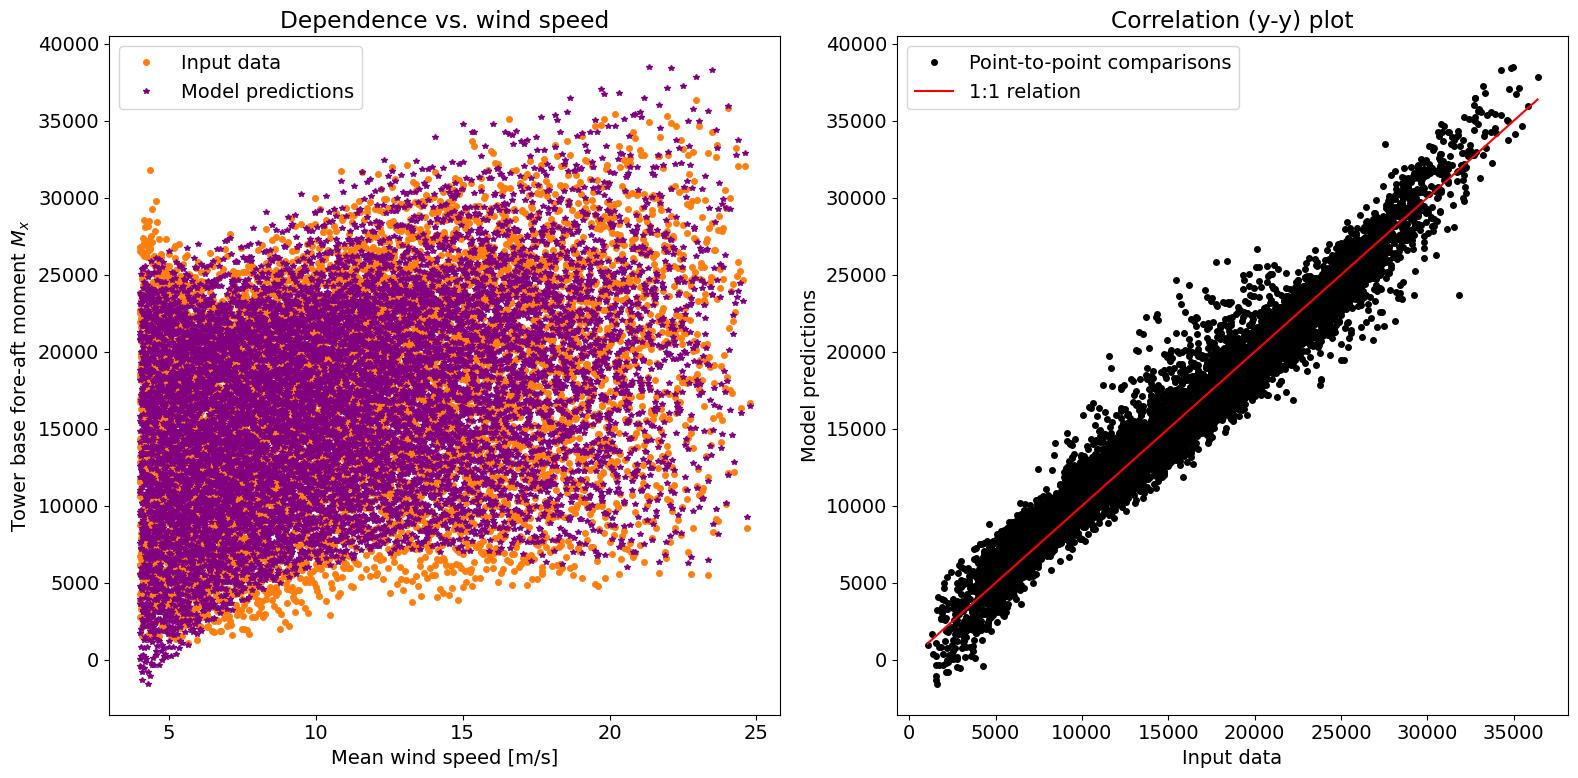

In [5]:
# VISUALISE RESULTS FROM THE PREDICTION
plt.rc('font', size=14) 
fig2a,axs2a = plt.subplots(1,2,figsize = (16,8))
plt.setp(axs2a[0], title = 'Dependence vs. wind speed', xlabel = 'Mean wind speed [m/s]', ylabel = 'Tower base fore-aft moment $M_x$')
plt.setp(axs2a[1], title = 'Correlation (y-y) plot', xlabel = 'Input data', ylabel = 'Model predictions')
axs2a[0].plot(AllInputData['U'], AllTargetData['Blade_root_flapwise_M_x'],'o',markersize = 4,color = 'C1')
axs2a[0].plot(AllInputData['U'], Ypred_O3,'*', markersize = 4,color = 'purple')
axs2a[0].legend(['Input data','Model predictions'])
axs2a[1].plot(AllTargetData['Blade_root_flapwise_M_x'], Ypred_O3,'ok', markersize = 4)
axs2a[1].plot(np.array([np.min(AllTargetData['Blade_root_flapwise_M_x']), np.max(AllTargetData['Blade_root_flapwise_M_x'])]),\
             np.array([np.min(AllTargetData['Blade_root_flapwise_M_x']), np.max(AllTargetData['Blade_root_flapwise_M_x'])]),'-r')
axs2a[1].legend(['Point-to-point comparisons','1:1 relation'])
plt.tight_layout()             
plt.show()

In [6]:
Rsq_poly = 1 - np.sum( (Y1 - Ypred_O3)**2) / np.sum((Y1 - np.mean(Y1))**2)
Rsq_corr_poly = (np.corrcoef(Y1,Ypred_O3)[0,1])**2 # R-squared with the correlation coefficient
RMSE_poly = np.sqrt( np.mean((Y1 - Ypred_O3)**2))
print('R-square of polynomial model: ' + str(Rsq_poly))
print('R-square computed through correlations: ' + str(Rsq_corr_poly))
print('RMSE of polynomial model: ' + str(RMSE_poly))

R-square of polynomial model: 0.9543421453167475
R-square computed through correlations: 0.9543421453167471
RMSE of polynomial model: 1418.2512982146113


In [7]:
epsilon = Y1 - Ypred_O3
bias = np.mean(epsilon)
variance = np.var(epsilon)
print('Bias of polynomial model: ' + str(bias))
print('Variance of polynomial model: ' + str(variance))

Bias of polynomial model: -1.269027617347533e-11
Variance of polynomial model: 2011436.7448874305


### Model 1.1: Random Forest

In [8]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

# Create a Random Forest Regressor model
RFregressor = RandomForestRegressor(n_estimators=60, random_state=1)

In [9]:
# Split the data into training and testing sets
Xtrain, Xtest, Ytrain, Ytest = train_test_split(X, Y1, test_size=0.2, random_state=1, shuffle=True)

# Fit the model
RFregressor.fit(Xtrain, Ytrain)
Ypred_RF = RFregressor.predict(Xtest)

# Calculate R², RMSE, and MAE for the Random Forest model
r2_RF = r2_score(Ytest, Ypred_RF)
rmse_RF = np.sqrt(mean_squared_error(Ytest, Ypred_RF))
mae_RF = mean_absolute_error(Ytest, Ypred_RF)

In [10]:
# Get the feature importances from the Random Forest model
print(f"RF Test R²   = {r2_RF:.4f}")
print(f"RF Test RMSE = {rmse_RF:.4f}")
print(f"RF Test MAE  = {mae_RF:.4f}")

# Additonal info for the table 
info_RF_v1 = "No. of estimators = 60"

RF Test R²   = 0.9611
RF Test RMSE = 1330.3477
RF Test MAE  = 887.2984


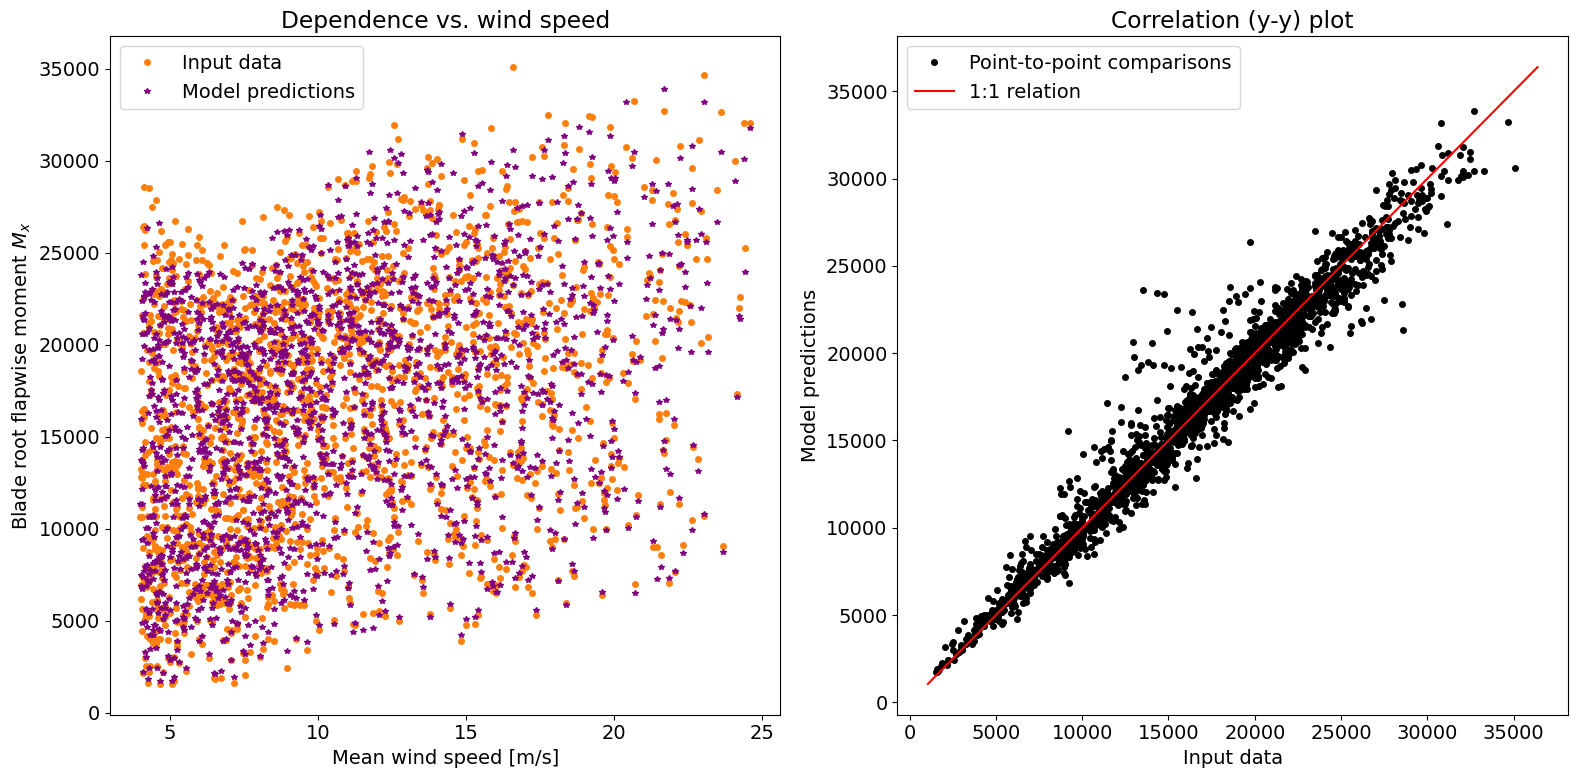

In [11]:
# VISUALISE RESULTS FROM THE PREDICTION
plt.rc('font', size=14) 
fig2b,axs2b = plt.subplots(1,2,figsize = (16,8))

plt.setp(axs2b[0], title = 'Dependence vs. wind speed', xlabel = 'Mean wind speed [m/s]', ylabel = 'Blade root flapwise moment $M_x$')
plt.setp(axs2b[1], title = 'Correlation (y-y) plot', xlabel = 'Input data', ylabel = 'Model predictions')

axs2b[0].plot(Xtest[:,0], Ytest,'o', markersize = 4,color = 'C1')
axs2b[0].plot(Xtest[:,0], Ypred_RF,'*',markersize = 4,color = 'purple')
axs2b[0].legend(['Input data', 'Model predictions'])

axs2b[1].plot(Ytest, Ypred_RF,'ok',markersize = 4)
axs2b[1].plot(np.array([np.min(AllTargetData['Blade_root_flapwise_M_x']), np.max(AllTargetData['Blade_root_flapwise_M_x'])]),\
             np.array([np.min(AllTargetData['Blade_root_flapwise_M_x']), np.max(AllTargetData['Blade_root_flapwise_M_x'])]),'-r')
axs2b[1].legend(['Point-to-point comparisons','1:1 relation'])

plt.tight_layout()             
plt.show()

### Model 1.2: Random Forest 2

In [12]:
# Create a Random Forest Regressor model
RFregressor = RandomForestRegressor(n_estimators=10, random_state=1)

# Split the data into training and testing sets
Xtrain, Xtest, Ytrain, Ytest = train_test_split(X, Y1, test_size=0.2, random_state=1, shuffle=True)

# Fit the model
RFregressor.fit(Xtrain, Ytrain)
Ypred_RF = RFregressor.predict(Xtest)

# Calculate R², RMSE, and MAE for the Random Forest model
r2_RF_v2 = r2_score(Ytest, Ypred_RF)
rmse_RF_v2 = np.sqrt(mean_squared_error(Ytest, Ypred_RF))
mae_RF_v2 = mean_absolute_error(Ytest, Ypred_RF)

# Additonal info for the table 
info_RF_v2 = "No. of estimators = 10"

### Model 2.1: Artificial Neural Network

In [13]:
import sklearn
import sklearn.neural_network

# Normalize the dataset
Xscaler = sklearn.preprocessing.StandardScaler()
Yscaler = sklearn.preprocessing.StandardScaler()

Xscaler = Xscaler.fit(AllInputData.values)
Yscaler = Yscaler.fit(AllTargetData['Blade_root_flapwise_M_x'].values.reshape(-1,1))

# Split into training and testing
TrainTestRatio = 0.8
N = len(AllInputData)
Xtrain = Xscaler.transform(AllInputData.values[0:int(N*TrainTestRatio),:])
Xtest = Xscaler.transform(AllInputData.values[int(N*TrainTestRatio):,:])

Ytrain = Yscaler.transform(AllTargetData['Blade_root_flapwise_M_x'].values.reshape(-1,1))[0:int(N*TrainTestRatio),:]
Ytest = Yscaler.transform(AllTargetData['Blade_root_flapwise_M_x'].values.reshape(-1,1))[int(N*TrainTestRatio):,:]

In [14]:
ANNmodel = sklearn.neural_network.MLPRegressor()
ANNmodel.set_params(activation = 'relu', hidden_layer_sizes = (10, 10))
ANNmodel.fit(Xtrain, Ytrain)

c:\Users\natal\repos\OceanCourses\.ocean\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:1775: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(10, ...)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when solver='sgd'.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",200
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [15]:
# Compute Model Predictions for the whole dataset
Yout = Yscaler.inverse_transform(ANNmodel.predict(Xtrain).reshape(-1, 1))
Yout_test = Yscaler.inverse_transform(ANNmodel.predict(Xtest).reshape(-1, 1))

In [16]:
Ytest_true = Yscaler.inverse_transform(Ytest)

r2_ann = sklearn.metrics.r2_score(Ytest_true, Yout_test)
rmse_ann = np.sqrt(sklearn.metrics.mean_squared_error(Ytest_true, Yout_test))
mae_ann = sklearn.metrics.mean_absolute_error(Ytest_true, Yout_test)

# Print the stats 
print( 'R2 of ANN model: ' + str(r2_ann))
print( 'RMSE of ANN model: ' + str(rmse_ann))
print( 'MAE of ANN model: ' + str(mae_ann))

# Additonal info for the table
info_ann = "Hidden Layers = (10, 10), Activation = ReLU"

R2 of ANN model: 0.9666887627013494
RMSE of ANN model: 1214.2521243314893
MAE of ANN model: 844.2505261698504


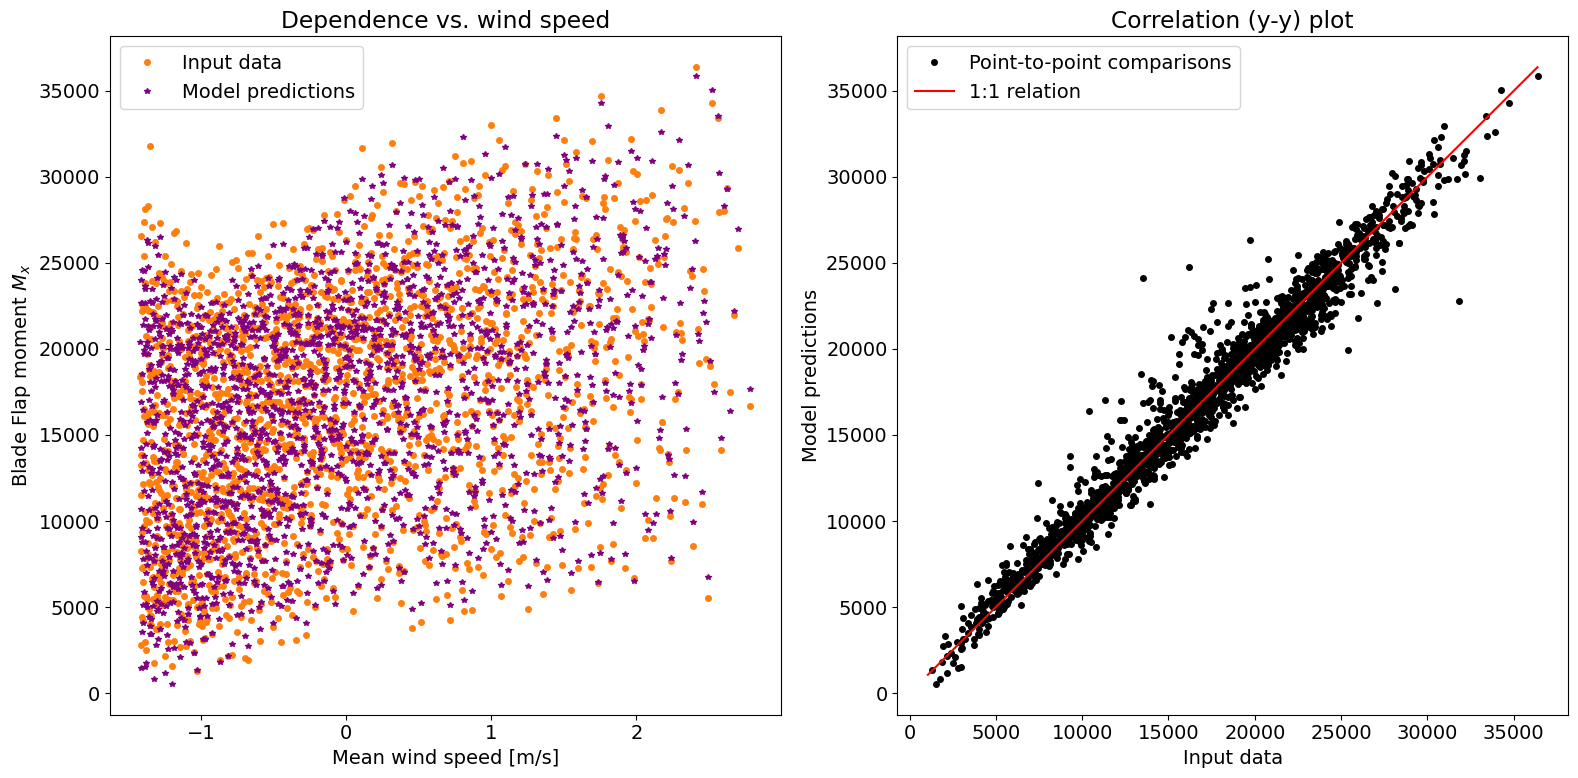

In [17]:
# VISUALISE RESULTS FROM THE PREDICTION 
plt.rc('font', size=14) 
fig3,axs3 = plt.subplots(1,2,figsize = (16,8))
plt.setp(axs3[0], title = 'Dependence vs. wind speed', xlabel = 'Mean wind speed [m/s]', ylabel = 'Blade Flap moment $M_x$')
plt.setp(axs3[1], title = 'Correlation (y-y) plot', xlabel = 'Input data', ylabel = 'Model predictions')
axs3[0].plot(Xtest[:,0],Yscaler.inverse_transform(Ytest),'o', markersize = 4, color = 'C1')
axs3[0].plot(Xtest[:,0],Yout_test,'*', markersize = 4, color = 'purple')
axs3[0].legend(['Input data','Model predictions'])
axs3[1].plot(Yscaler.inverse_transform(Ytest),Yout_test,'ok', markersize = 4)
axs3[1].plot(np.array([np.min(AllTargetData['Blade_root_flapwise_M_x']), np.max(AllTargetData['Blade_root_flapwise_M_x'])]),\
             np.array([np.min(AllTargetData['Blade_root_flapwise_M_x']), np.max(AllTargetData['Blade_root_flapwise_M_x'])]),'-r')
axs3[1].legend(['Point-to-point comparisons','1:1 relation'])
plt.tight_layout()     
plt.show()

### Model 2.2: Artificial Neural Network 2

In [18]:
# Performance of different activation functions -> TANH
ANNmodel = sklearn.neural_network.MLPRegressor()
ANNmodel.set_params(activation = 'tanh', hidden_layer_sizes = (8, 8))
ANNmodel.fit(Xtrain, Ytrain)

# Compute Model Predictions for the whole dataset
Yout = Yscaler.inverse_transform(ANNmodel.predict(Xtrain).reshape(-1, 1))
Yout_test = Yscaler.inverse_transform(ANNmodel.predict(Xtest).reshape(-1, 1))

Ytest_true = Yscaler.inverse_transform(Ytest)

r2_ann_v2 = sklearn.metrics.r2_score(Ytest_true, Yout_test)
rmse_ann_v2 = np.sqrt(sklearn.metrics.mean_squared_error(Ytest_true, Yout_test))
mae_ann_v2 = sklearn.metrics.mean_absolute_error(Ytest_true, Yout_test)

# Additonal info for the table
info_ann_v2 = "Hidden Layers = (8, 8), Activation = Tanh"

c:\Users\natal\repos\OceanCourses\.ocean\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:1775: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


### Evaluation

In [19]:
import prettytable as pt

# Compare R2, RMSE and score of RF and ANN models 
table = pt.PrettyTable()
table.field_names = ["Model", "Info", "R²", "RMSE", "MAE"]
table.add_row(["Random Forest 1", info_RF_v1, f"{r2_RF:.4f}", f"{rmse_RF:.4f}", f"{mae_RF:.4f}"])
table.add_row(["Random Forest 2", info_RF_v2, f"{r2_RF_v2:.4f}", f"{rmse_RF_v2:.4f}", f"{mae_RF_v2:.4f}"])
table.add_row(["Artificial Neural Network 1", info_ann, f"{r2_ann:.4f}", f"{rmse_ann:.4f}", f"{mae_ann:.4f}"])
table.add_row(["Artificial Neural Network 2", info_ann_v2, f"{r2_ann_v2:.4f}", f"{rmse_ann_v2:.4f}", f"{mae_ann_v2:.4f}"])

print(table)

+-----------------------------+---------------------------------------------+--------+-----------+----------+
|            Model            |                     Info                    |   R²   |    RMSE   |   MAE    |
+-----------------------------+---------------------------------------------+--------+-----------+----------+
|       Random Forest 1       |            No. of estimators = 60           | 0.9611 | 1330.3477 | 887.2984 |
|       Random Forest 2       |            No. of estimators = 10           | 0.9565 | 1407.4778 | 937.1736 |
| Artificial Neural Network 1 | Hidden Layers = (10, 10), Activation = ReLU | 0.9667 | 1214.2521 | 844.2505 |
| Artificial Neural Network 2 |  Hidden Layers = (8, 8), Activation = Tanh  | 0.9678 | 1193.5071 | 833.3266 |
+-----------------------------+---------------------------------------------+--------+-----------+----------+


## Getting the $X_M$ of the chosen model -  Artificial Neural Network 2 

In [ ]:
from sklearn.utils import resample
from sklearn.neural_network import MLPRegressor

N_models = 50
ANN_models = []

# Keep one common scaling for all models
Xscaler = sklearn.preprocessing.StandardScaler().fit(AllInputData.values)
Yscaler = sklearn.preprocessing.StandardScaler().fit(AllTargetData["Blade_root_flapwise_M_x"].values.reshape(-1, 1))

X_all = Xscaler.transform(AllInputData.values)
Y_all = Yscaler.transform(AllTargetData["Blade_root_flapwise_M_x"].values.reshape(-1, 1)).ravel()

for model_number in range(N_models):
    # Bootstrap the training data
    X_boot, Y_boot = resample(X_all, Y_all, replace=True, n_samples=len(X_all), random_state=model_number,)
    model = MLPRegressor(activation="tanh", hidden_layer_sizes=(8, 8), max_iter=5000, random_state=model_number,)
    model.fit(X_boot, Y_boot)
    ANN_models.append(model)

In [ ]:
ensemble_predictions_scaled = np.column_stack([
    model.predict(Xtest)
    for model in ANN_models
])

# Convert every model prediction back to physical DEL units
ensemble_predictions = np.column_stack([
    Yscaler.inverse_transform(
        ensemble_predictions_scaled[:, i].reshape(-1, 1)
    ).ravel()
    for i in range(N_models)
])

YM_mean = np.mean(ensemble_predictions, axis=1)
YM_std = np.std(ensemble_predictions, axis=1)

print("Mean model uncertainty:", np.mean(YM_std))
print("Maximum model uncertainty:", np.max(YM_std))

Mean model uncertainty: 258.73794146786764
Maximum model uncertainty: 1001.3838345556505


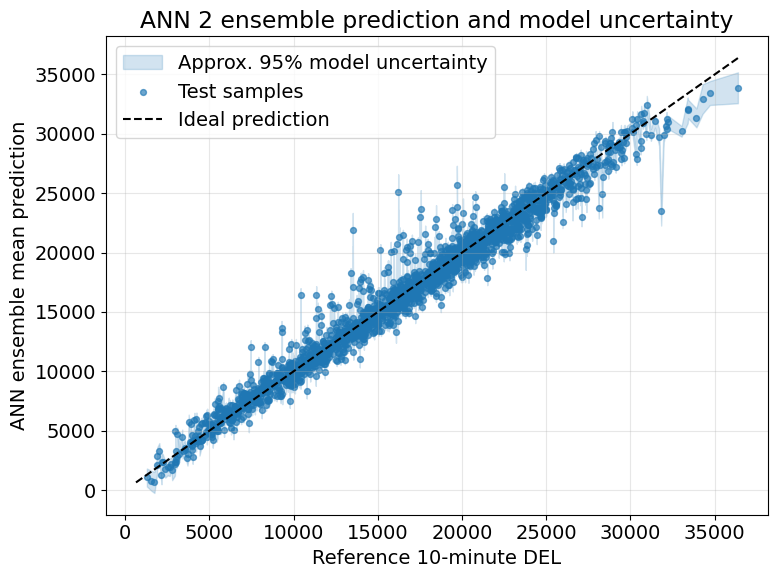

In [34]:
import numpy as np
import matplotlib.pyplot as plt

# Predictions from all ANN ensemble members on the test set
ensemble_predictions_scaled = np.column_stack([
    model.predict(Xtest)
    for model in ANN_models
])

# Convert each model prediction back to DEL units
ensemble_predictions = np.column_stack([
    Yscaler.inverse_transform(
        ensemble_predictions_scaled[:, i].reshape(-1, 1)
    ).ravel()
    for i in range(len(ANN_models))
])

YM_mean = np.mean(ensemble_predictions, axis=1)
YM_std = np.std(ensemble_predictions, axis=1)

# Approximate 95% model uncertainty interval
YM_lower = YM_mean - 1.96 * YM_std
YM_upper = YM_mean + 1.96 * YM_std

Ytest_physical = Yscaler.inverse_transform(
    Ytest.reshape(-1, 1)
).ravel()

# Sort for a cleaner uncertainty band
order = np.argsort(Ytest_physical)
Y_sorted = Ytest_physical[order]
mean_sorted = YM_mean[order]
lower_sorted = YM_lower[order]
upper_sorted = YM_upper[order]

plt.figure(figsize=(8, 6))

plt.fill_between(
    Y_sorted,
    lower_sorted,
    upper_sorted,
    color="tab:blue",
    alpha=0.2,
    label="Approx. 95% model uncertainty",
)

plt.scatter(
    Ytest_physical,
    YM_mean,
    s=18,
    alpha=0.65,
    label="Test samples",
)

min_value = min(Ytest_physical.min(), YM_mean.min())
max_value = max(Ytest_physical.max(), YM_mean.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "k--",
    label="Ideal prediction",
)

plt.xlabel("Reference 10-minute DEL")
plt.ylabel("ANN ensemble mean prediction")
plt.title("ANN 2 ensemble prediction and model uncertainty")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

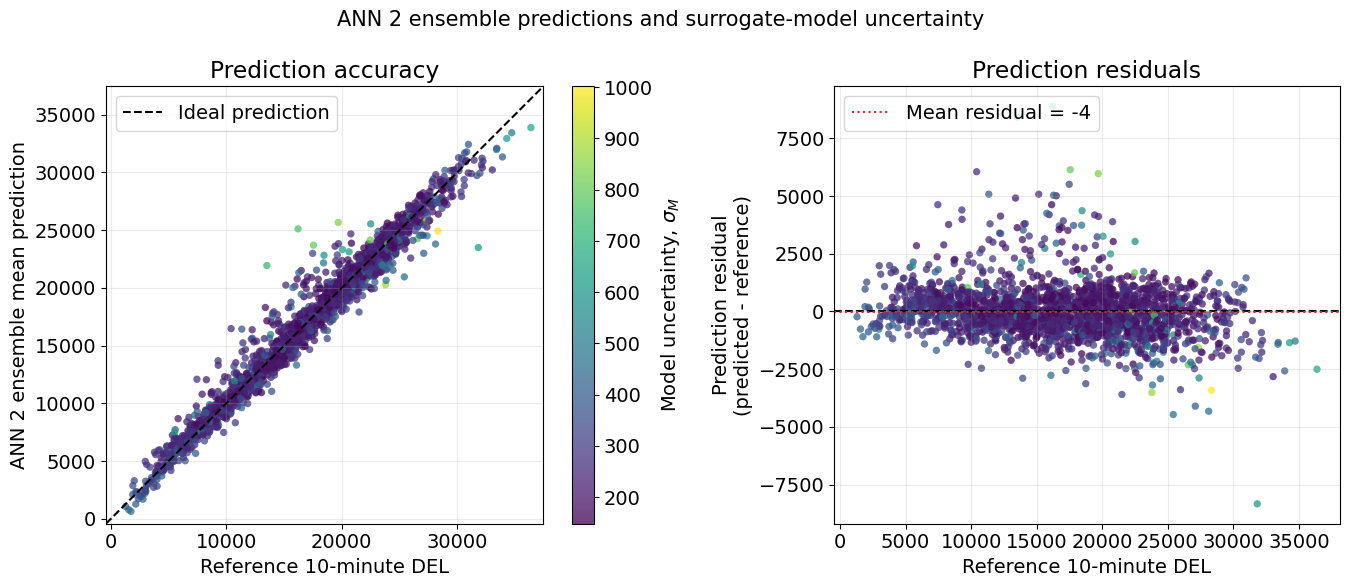

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# Convert the test targets back to physical DEL units
Ytest_physical = Yscaler.inverse_transform(
    Ytest.reshape(-1, 1)
).ravel()

# Ensemble predictions in physical DEL units
ensemble_predictions_scaled = np.column_stack([
    model.predict(Xtest).ravel()
    for model in ANN_models
])

ensemble_predictions = np.column_stack([
    Yscaler.inverse_transform(
        ensemble_predictions_scaled[:, i].reshape(-1, 1)
    ).ravel()
    for i in range(len(ANN_models))
])

# Mean and standard deviation of the ensemble
YM_mean = np.mean(ensemble_predictions, axis=1)
YM_std = np.std(ensemble_predictions, axis=1)

# Approximate 95% model uncertainty interval
uncertainty_95 = 1.96 * YM_std

# Residual: positive means the ANN overpredicts
residuals = YM_mean - Ytest_physical

# Common axis limits
minimum = min(Ytest_physical.min(), YM_mean.min())
maximum = max(Ytest_physical.max(), YM_mean.max())
margin = 0.03 * (maximum - minimum)

axis_min = minimum - margin
axis_max = maximum + margin

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6),
    gridspec_kw={"width_ratios": [1.15, 1]},
)

# ------------------------------------------------------------
# Left panel: parity plot
# ------------------------------------------------------------
scatter = axes[0].scatter(
    Ytest_physical,
    YM_mean,
    c=YM_std,
    cmap="viridis",
    s=28,
    alpha=0.75,
    edgecolors="none",
)

axes[0].plot(
    [axis_min, axis_max],
    [axis_min, axis_max],
    "k--",
    linewidth=1.5,
    label="Ideal prediction",
)

axes[0].set_xlim(axis_min, axis_max)
axes[0].set_ylim(axis_min, axis_max)
axes[0].set_aspect("equal", adjustable="box")

axes[0].set_xlabel("Reference 10-minute DEL")
axes[0].set_ylabel("ANN 2 ensemble mean prediction")
axes[0].set_title("Prediction accuracy")

axes[0].grid(alpha=0.25)
axes[0].legend(loc="upper left")

colorbar = fig.colorbar(scatter, ax=axes[0])
colorbar.set_label("Model uncertainty, $\\sigma_M$")

# ------------------------------------------------------------
# Right panel: residual plot
# ------------------------------------------------------------
axes[1].scatter(
    Ytest_physical,
    residuals,
    c=YM_std,
    cmap="viridis",
    s=28,
    alpha=0.75,
    edgecolors="none",
)

axes[1].axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.5,
)

axes[1].axhline(
    np.mean(residuals),
    color="tab:red",
    linestyle=":",
    linewidth=1.5,
    label=f"Mean residual = {np.mean(residuals):.0f}",
)

axes[1].set_xlabel("Reference 10-minute DEL")
axes[1].set_ylabel("Prediction residual\n(predicted - reference)")
axes[1].set_title("Prediction residuals")

axes[1].grid(alpha=0.25)
axes[1].legend(loc="upper left")

fig.suptitle(
    "ANN 2 ensemble predictions and surrogate-model uncertainty",
    fontsize=15,
)

fig.tight_layout()
plt.show()